# **Project**
In this project, we use publicly available e-commerce transaction data and supervised machine learning techniques to build a model that predicts which customers are most likely to become repeat purchasers. This will help WitOmni identify high-value customer segments, prioritize marketing efforts, and develop more effective customer retention strategies.

# **Imports and Setup**

In [ ]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
import tensorflow.keras as keras
from sklearn.preprocessing import StandardScaler
import time
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, precision_score, average_precision_score, recall_score, f1_score
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold

In [ ]:
pip install ucimlrepo

## **`Task 2: Data Analysis & Cleaning`**

Now that we have the full dataframe, we can define the target variable `y`. A 'repeat purchaser' can be defined as a customer who has bought again in a future window. We can identify these customers by counting the number of unique `InvoiceNo` per `CustomerID`.

In [ ]:
#Initial data loading and prep — completed by Syeda
from ucimlrepo import fetch_ucirepo

# fetch dataset
online_retail = fetch_ucirepo(id=352)

# data (as pandas dataframes)
X = online_retail.data.features
y = online_retail.data.targets

# metadata
print(online_retail.metadata)

# variable information
print(online_retail.variables)

df = pd.concat([online_retail.data.ids, X], axis=1)

{'uci_id': 352, 'name': 'Online Retail', 'repository_url': 'https://archive.ics.uci.edu/dataset/352/online+retail', 'data_url': 'https://archive.ics.uci.edu/static/public/352/data.csv', 'abstract': 'This is a transactional data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate', 'Sequential', 'Time-Series'], 'num_instances': 541909, 'num_features': 6, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': None, 'index_col': ['InvoiceNo', 'StockCode'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2015, 'last_updated': 'Mon Oct 21 2024', 'dataset_doi': '10.24432/C5BW33', 'creators': ['Daqing Chen'], 'intro_paper': {'ID': 361, 'type': 'NATIVE', 'title': 'Data mining for the online retail industry: A case study of RFM model-based customer segmenta

This may be important from above

'variable_info': "InvoiceNo: Invoice number. Nominal, a 6-digit integral number uniquely assigned to each transaction. If this code starts with letter 'c', it indicates a cancellation.

Since the dataset does not come with a predefined target variable (`y`), we need to construct it based on the problem statement. Our goal is to predict 'repeat purchasers'. First, let's create a complete DataFrame by combining the features (`X`) with the ID columns (`InvoiceNo`, `StockCode`) which were separated.

We examined the dataset's dimensions, data types, missing values, and duplicate records before beginning the cleaning process. This allowed us to understand the initial data quality and identify issues that needed to be addressed before further analysis.

In [ ]:
#total rows/columns
print("Dataset shape:", df.shape)
#check for correctly loaded data types
print("\nData types:", df.dtypes)
#check for any duplicate values
print("\nNumber of duplicate rows:", df.duplicated().sum())
#check for total missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (541909, 8)

Data types: InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object

Number of duplicate rows: 5268

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [ ]:
#check for total count of duplicate values
duplicates=df[df.duplicated(keep=False)]
duplicates=duplicates.sort_values(["InvoiceNo","StockCode"])
print("Duplicate Rows:",duplicates.shape[0])
print("Unique Invoices:",duplicates["InvoiceNo"].nunique())
duplicates.head(10)

Duplicate Rows: 10147
Unique Invoices: 1933


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,12/1/2010 11:49,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,12/1/2010 11:49,1.65,17920.0,United Kingdom


In [ ]:
#dropping duplicates
before_drop_duplicates=df.shape[0]
df=df.drop_duplicates()
print("Before Rows:",before_drop_duplicates)
print("After Rows:",df.shape[0])
print("Removed Rows", before_drop_duplicates-df.shape[0])

Before Rows: 541909
After Rows: 536641
Removed Rows 5268



# Data Cleaning and Preparation for Prediction





summary:
- split the data by a date to have a past and 'future' to assess our predictions (label = future, features = past)
- cleaned/handled null or invalid data
- merged features + label into a cleaned df, one-row-per-customer (instead of each row representing a transaction)

please read through and verify if this makes any sense because I'm not sure if I'm approaching/understanding correctly

Prediction task: for each customer, will they purchase again in the future? -> marketing can prioritize their efforts develop more effective customer retention strategies.

In [ ]:
print(df.isna().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


The above cell told us that 135,080 rows had no CustomerID

In [ ]:
display(df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


Before splitting the data into a past and future, clean the data: remove missing CustomerID rows, cancellations, invalid purcahses

In [ ]:
df = df.dropna(subset=['CustomerID']) # Remove any row where CustomerID is missing
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')] # Remove Cancellations: if InvoiceNo starts with the letter "C", that transaction is a cancellation, not a real purchase
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)] # Remove any rows where quantity or price are non-pos (just being cautious)
print("Cleaned shape:", df.shape)

Cleaned shape: (392692, 8)


In [ ]:
#codes that may appear to be StockCode but aren't exactly products (postage, manual adjustments, fees, donations, samples)
non_products=["POST","DOT","C2","M","m","BANK CHARGES",
              "AMAZONFEE","CRUK","S","D"]

df=df[~df["StockCode"].astype(str).isin(non_products)] #Keeps ownly the rows whose StockCode isn't in that list
print("Shape after removing non-products:",df.shape) #Removing postage, fees and adjustment codes means total_spent measures money spent on actual products instead of shipping and charges mixed together!

Shape after removing non-products: (391153, 8)


Prepare the data for prediction by splitting it into past and 'future' using a cutoff date

In [ ]:
# Make sure InvoiceDate is datetime, and pick a cutoff to split past vs future for prediction
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
cutoff_date = df['InvoiceDate'].quantile(0.7) # use date where 70% of transaction volume occurred as data, everything after is for prediction

past = df[df['InvoiceDate'] <= cutoff_date]
future = df[df['InvoiceDate'] > cutoff_date]

print("Cutoff date:", cutoff_date)
print("Past rows:", past.shape[0], "| Future rows:", future.shape[0])

Cutoff date: 2011-10-07 13:34:00
Past rows: 273818 | Future rows: 117335


label (y) uses the 'future' data

In [ ]:
# Cleaning: only look at customers who had at least one purchase in the 'past' period
past_customers = past['CustomerID'].dropna().unique()

# Label: did these customers buy again in the 'future' period?
future_customers = set(future['CustomerID'].dropna().unique())

labels = pd.DataFrame({'CustomerID': past_customers})
labels['is_repeat_purchaser'] = labels['CustomerID'].isin(future_customers).astype(int)

display(labels.head())
print(labels['is_repeat_purchaser'].value_counts())
print(f"Percentage of repeat purchasers: {labels['is_repeat_purchaser'].mean() * 100:.2f}%")

,CustomerID,is_repeat_purchaser
0,17850.0,0
1,13047.0,1
2,12583.0,1
3,13748.0,0
4,15100.0,0


is_repeat_purchaser
0    1905
1    1796
Name: count, dtype: int64
Percentage of repeat purchasers: 48.53%


#**Task 4: Engineer Customer-Level Features**

We used "CustomerID", "InvoiceDate", "Quantity", and "UnitPrice"to build three customer-level features from the "past" transaction data: **purchase frequency**, **recency**, and **average order value**. Transactions were grouped by 'CustomerID', each feature was calculated, and the results were checked for missing and unusual values before merging with the repeat-purchaser labels to form the final modeling dataset.                                                               -**Purchase Frequency**: number of unique invoices per customer.                          - **Recency**: Days between the cutoff date and each customer's last purchase in the "past" period (lower=more recent).
-**Average Order Value**: total amount spent divided by number of orders.


In [ ]:
#Customer-level feature engineering — completed by Marissa

past = past.copy()
past["TotalPrice"] = past["Quantity"] * past["UnitPrice"]

customer_features = past.groupby("CustomerID").agg(
    total_spent=("TotalPrice", "sum"),
    PurchaseFrequency=("InvoiceNo", "nunique"),
    LastPurchaseDate=("InvoiceDate", "max")
).reset_index()
#change to RecencyDays
customer_features["Recency"] = (
    cutoff_date - customer_features["LastPurchaseDate"]
).dt.days

customer_features["AverageOrderValue"] = (
    customer_features["total_spent"] / customer_features["PurchaseFrequency"]
)

# checking missing values & unusual data

print("Missing values: ")
print(customer_features[["total_spent","PurchaseFrequency", "Recency", "AverageOrderValue"]].isna().sum())


print("\nNegative Recency (should be 0): ", (customer_features["Recency"]< 0).sum())
print("\nZero PurchaseFrequency (should be 0): ", (customer_features["PurchaseFrequency"] <= 0).sum())

# checking summary statistics
display(customer_features[["total_spent","PurchaseFrequency", "Recency", "AverageOrderValue"]].describe())

#Merge with labels to build the final modeling dataset
df = customer_features.merge(labels, on='CustomerID')
display(df.head(10))
print(df.shape)

Missing values: 
total_spent          0
PurchaseFrequency    0
Recency              0
AverageOrderValue    0
dtype: int64

Negative Recency (should be 0):  0

Zero PurchaseFrequency (should be 0):  0


,total_spent,PurchaseFrequency,Recency,AverageOrderValue
count,3701.000000,3701.000000,3701.000000,3701.000000
mean,1720.078409,3.653877,91.772224,405.768122
std,7243.264289,6.206658,88.599385,1369.232570
min,2.900000,1.000000,0.000000,2.900000
25%,283.730000,1.000000,16.000000,176.266667
50%,594.000000,2.000000,60.000000,291.320000
75%,1429.840000,4.000000,148.000000,428.300000
max,203146.860000,143.000000,310.000000,77183.600000


,CustomerID,total_spent,PurchaseFrequency,LastPurchaseDate,Recency,AverageOrderValue,is_repeat_purchaser
0,12346.0,77183.60,1,2011-01-18 10:01:00,262,77183.600,0
1,12347.0,2790.86,5,2011-08-02 08:48:00,66,558.172,1
2,12348.0,1437.24,4,2011-09-25 13:13:00,12,359.310,0
3,12350.0,294.40,1,2011-02-02 16:01:00,246,294.400,0
4,12352.0,1154.01,6,2011-09-28 14:58:00,8,192.335,1
5,12353.0,89.00,1,2011-05-19 17:47:00,140,89.000,0
6,12354.0,1079.40,1,2011-04-21 13:11:00,169,1079.400,0
7,12355.0,459.40,1,2011-05-09 13:49:00,150,459.400,0
8,12356.0,2429.08,2,2011-04-08 12:33:00,182,1214.540,1
9,12358.0,404.86,1,2011-07-12 10:04:00,87,404.860,1


(3701, 7)


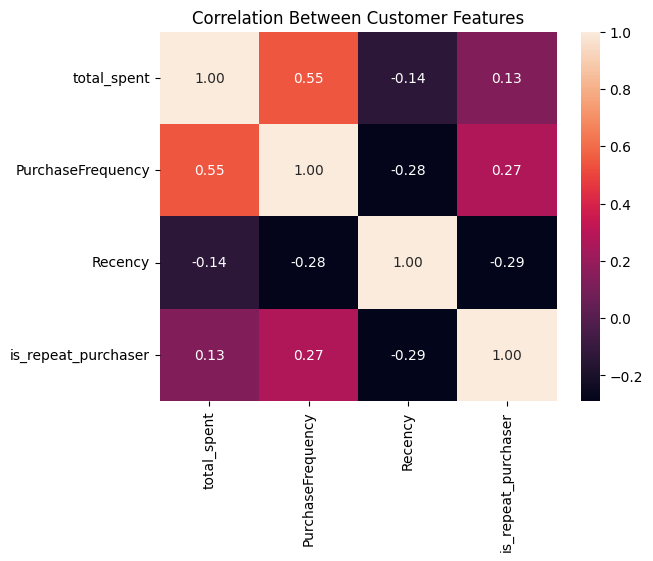

In [ ]:
corr = df[[
    "total_spent",
    "PurchaseFrequency",
    "Recency",
    "is_repeat_purchaser"
]].corr()

sns.heatmap(corr, annot=True, fmt=".2f")

plt.title("Correlation Between Customer Features")
plt.show()

#**Task 3: Exploratory Data Analysis and Visualization**

In [ ]:
df.head()


,CustomerID,total_spent,PurchaseFrequency,LastPurchaseDate,Recency,AverageOrderValue,is_repeat_purchaser
0,12346.0,77183.60,1,2011-01-18 10:01:00,262,77183.600,0
1,12347.0,2790.86,5,2011-08-02 08:48:00,66,558.172,1
2,12348.0,1437.24,4,2011-09-25 13:13:00,12,359.310,0
3,12350.0,294.40,1,2011-02-02 16:01:00,246,294.400,0
4,12352.0,1154.01,6,2011-09-28 14:58:00,8,192.335,1


In [ ]:
print(df.shape)
print(df.isnull().sum())

(3701, 7)
CustomerID             0
total_spent            0
PurchaseFrequency      0
LastPurchaseDate       0
Recency                0
AverageOrderValue      0
is_repeat_purchaser    0
dtype: int64


In [ ]:
df["is_repeat_purchaser"].value_counts()

,count
is_repeat_purchaser,
0,1905
1,1796


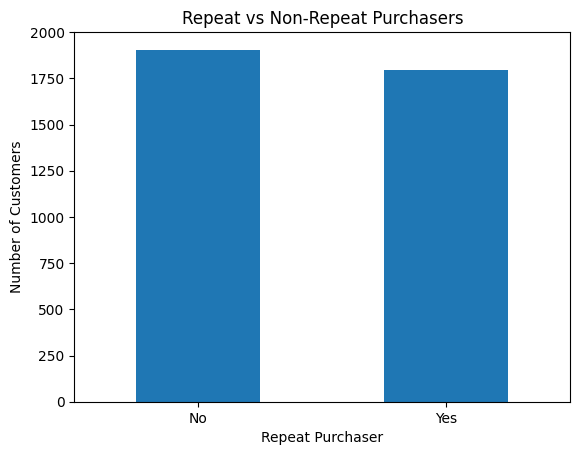

In [ ]:
df["is_repeat_purchaser"].value_counts().plot(kind="bar")

plt.title("Repeat vs Non-Repeat Purchasers")
plt.xlabel("Repeat Purchaser")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["No", "Yes"], rotation=0)

plt.show()

The target classes are fairly balanced. There are 1,914 non-repeat purchasers and 1,793 repeat purchasers, so there is not a major class imbalance.

In [ ]:
df.groupby("is_repeat_purchaser")["total_spent"].mean()

,total_spent
is_repeat_purchaser,
0,787.748080
1,2708.992261


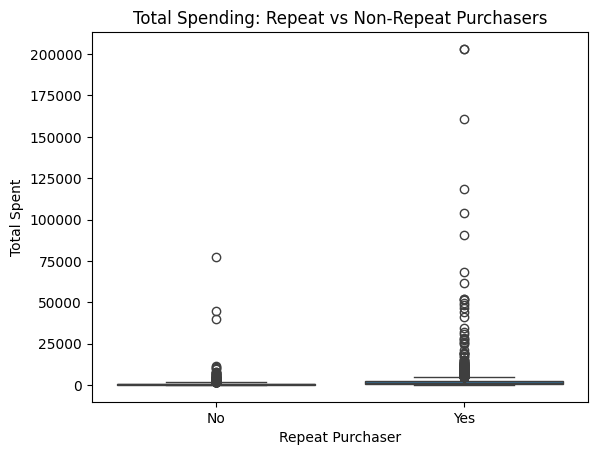

In [ ]:
sns.boxplot(
    data=df,
    x="is_repeat_purchaser",
    y="total_spent"
)

plt.title("Total Spending: Repeat vs Non-Repeat Purchasers")
plt.xlabel("Repeat Purchaser")
plt.ylabel("Total Spent")
plt.xticks([0, 1], ["No", "Yes"])

plt.show()

In [ ]:
df.groupby("is_repeat_purchaser")["PurchaseFrequency"].mean()

,PurchaseFrequency
is_repeat_purchaser,
0,2.027297
1,5.379176


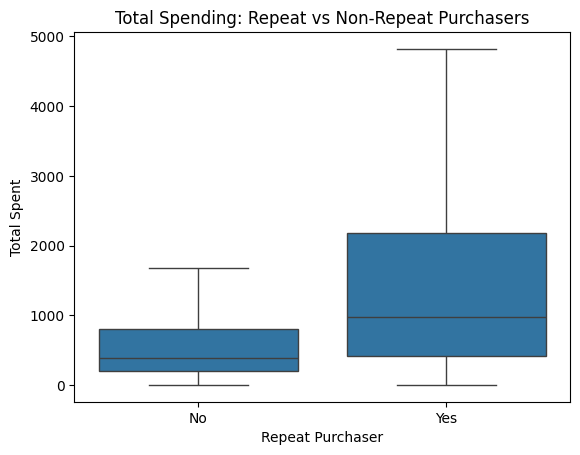

In [ ]:
sns.boxplot(
    data=df,
    x="is_repeat_purchaser",
    y="total_spent",
    showfliers=False
)

plt.title("Total Spending: Repeat vs Non-Repeat Purchasers")
plt.xlabel("Repeat Purchaser")
plt.ylabel("Total Spent")
plt.xticks([0, 1], ["No", "Yes"])

plt.show()

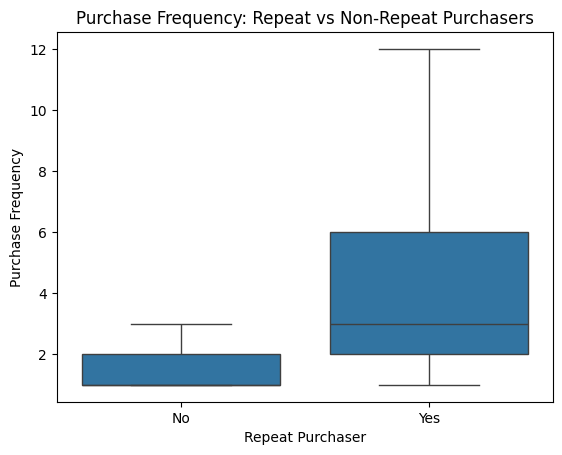

In [ ]:
sns.boxplot(
    data=df,
    x="is_repeat_purchaser",
    y="PurchaseFrequency",
    showfliers=False
)

plt.title("Purchase Frequency: Repeat vs Non-Repeat Purchasers")
plt.xlabel("Repeat Purchaser")
plt.ylabel("Purchase Frequency")
plt.xticks([0, 1], ["No", "Yes"])

plt.show()

In [ ]:
#Exploratory Data Analysis — completed by Meena

Repeat purchasers tend to spend more overall than non-repeat purchasers. The median and spending range are both higher for repeat purchasers.

Repeat purchasers had a higher purchase frequency in the past. Their median purchase frequency is around 3, compared with about 1 for non-repeat purchasers.

Customers who became repeat purchasers had more recent past purchases. On average, their last purchase was about 66 days ago compared with about 118 days for non-repeat purchasers.

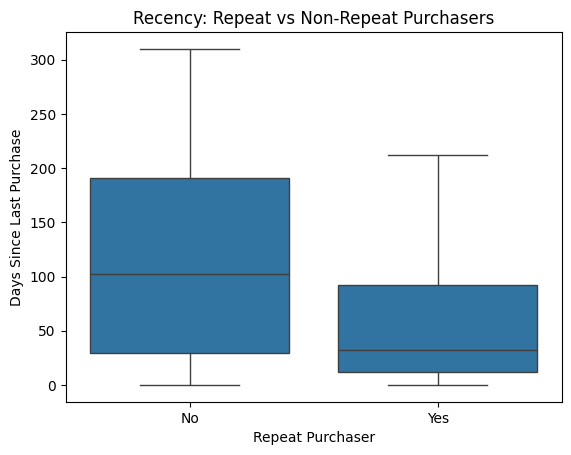

In [ ]:
sns.boxplot(
    data=df,
    x="is_repeat_purchaser",
    y="Recency",
    showfliers=False
)

plt.title("Recency: Repeat vs Non-Repeat Purchasers")
plt.xlabel("Repeat Purchaser")
plt.ylabel("Days Since Last Purchase")
plt.xticks([0, 1], ["No", "Yes"])

plt.show()

Repeat purchasers tend to have made their last purchase more recently. Their median recency is much lower than non-repeat purchasers.

In [ ]:
df[["total_spent", "PurchaseFrequency", "Recency", "is_repeat_purchaser"]].corr()

,total_spent,PurchaseFrequency,Recency,is_repeat_purchaser
total_spent,1.000000,0.545224,-0.135642,0.132583
PurchaseFrequency,0.545224,1.000000,-0.281646,0.269942
Recency,-0.135642,-0.281646,1.000000,-0.290119
is_repeat_purchaser,0.132583,0.269942,-0.290119,1.000000


Purchase frequency has a positive relationship with repeat purchasing, while recency has a negative relationship. This means customers who purchased more often and more recently were more likely to become repeat purchasers.

In [ ]:
df[["total_spent", "PurchaseFrequency", "Recency"]].describe()

,total_spent,PurchaseFrequency,Recency
count,3701.000000,3701.000000,3701.000000
mean,1720.078409,3.653877,91.772224
std,7243.264289,6.206658,88.599385
min,2.900000,1.000000,0.000000
25%,283.730000,1.000000,16.000000
50%,594.000000,2.000000,60.000000
75%,1429.840000,4.000000,148.000000
max,203146.860000,143.000000,310.000000


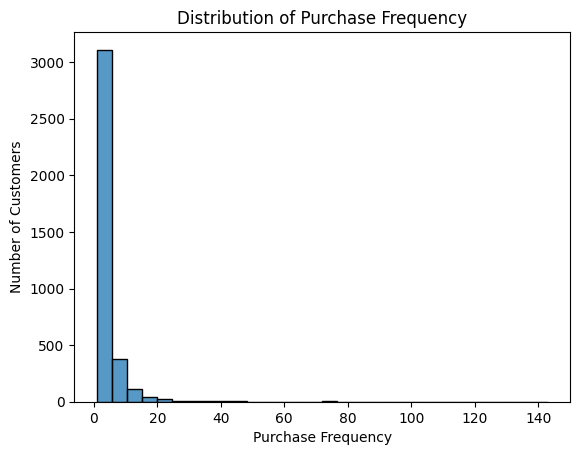

In [ ]:
sns.histplot(df["PurchaseFrequency"], bins=30)

plt.title("Distribution of Purchase Frequency")
plt.xlabel("Purchase Frequency")
plt.ylabel("Number of Customers")

plt.show()

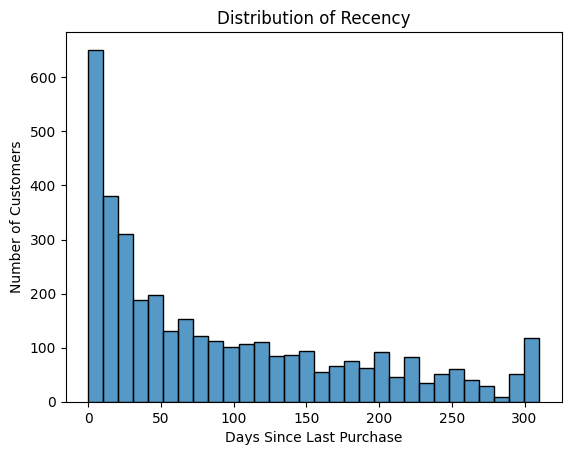

In [ ]:
sns.histplot(df["Recency"], bins=30)
plt.title("Distribution of Recency")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")

plt.show()


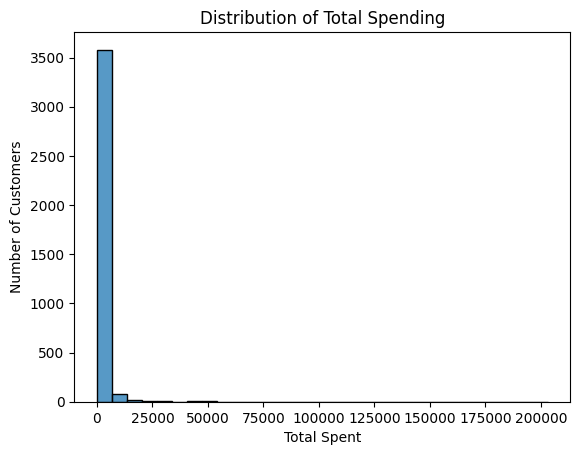

In [ ]:
sns.histplot(df["total_spent"], bins=30)

plt.title("Distribution of Total Spending")
plt.xlabel("Total Spent")
plt.ylabel("Number of Customers")

plt.show()

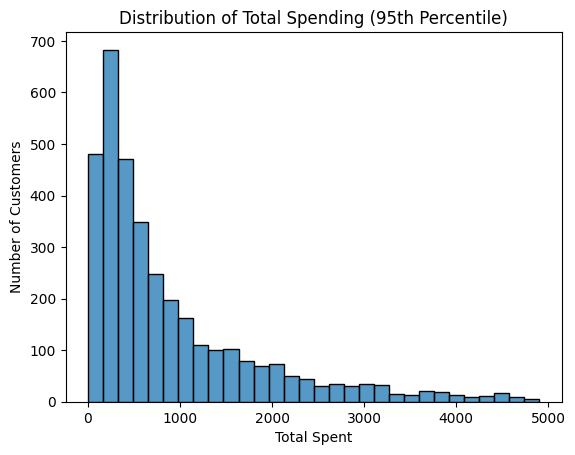

In [ ]:
limit = df["total_spent"].quantile(0.95)

sns.histplot(
    df[df["total_spent"] <= limit]["total_spent"],
    bins=30
)

plt.title("Distribution of Total Spending (95th Percentile)")
plt.xlabel("Total Spent")
plt.ylabel("Number of Customers")

plt.show()

Initial EDA Findings
* Repeat purchasers tend to spend more than non-repeat purchasers.
* Repeat purchasers purchase more frequently.
* Repeat purchasers tend to have purchased more recently.
* Purchase frequency has a positive relationship with repeat purchasing.
* Recency has a negative relationship with repeat purchasing.
* Purchase frequency is highly right-skewed; most customers made only a few purchases.
* Recency is right-skewed; many customers purchased recently, while fewer customers had long gaps since their last purchase.
* Total spending is highly right-skewed, with a small number of very high-spending customers.
* **What this means**:
These early results suggest that purchase frequency and recency may help predict which customers are likely to purchase again.



Summary Statistics and Key Predictive Features

In [ ]:
df.groupby("is_repeat_purchaser")["AverageOrderValue"].mean()

,AverageOrderValue
is_repeat_purchaser,
0,409.063072
1,402.273200


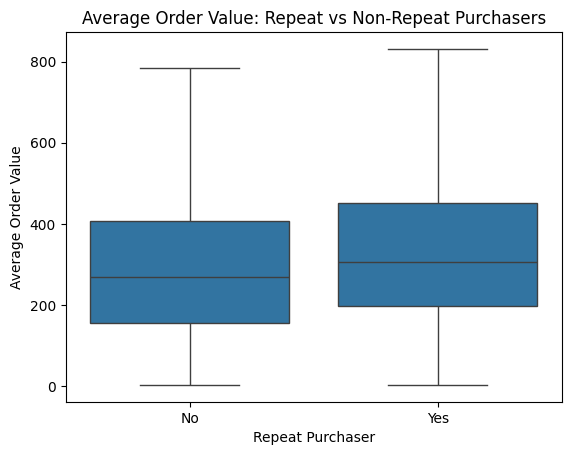

In [ ]:
sns.boxplot(
    data=df,
    x="is_repeat_purchaser",
    y="AverageOrderValue",
    showfliers=False
)


plt.title("Average Order Value: Repeat vs Non-Repeat Purchasers")
plt.xlabel("Repeat Purchaser")
plt.ylabel("Average Order Value")
plt.xticks([0, 1], ["No", "Yes"])

plt.show()

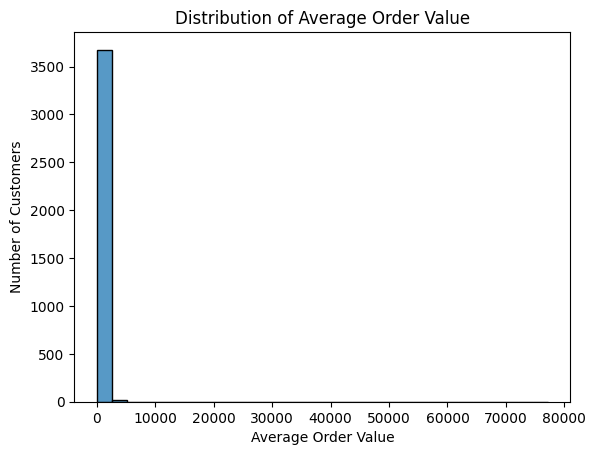

In [ ]:
sns.histplot(df["AverageOrderValue"], bins=30)

plt.title("Distribution of Average Order Value")
plt.xlabel("Average Order Value")
plt.ylabel("Number of Customers")

plt.show()
#

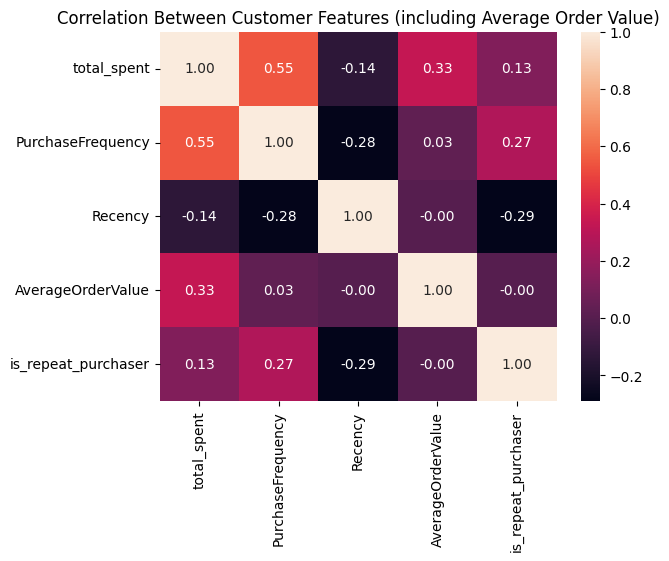

In [ ]:
#Updated correlation matrix including AverageOrderValue alongside the other features
corr_full = df[[
    "total_spent",
    "PurchaseFrequency",
    "Recency",
    "AverageOrderValue",
    "is_repeat_purchaser"
]].corr()

sns.heatmap(corr_full, annot=True, fmt=".2f")

plt.title("Correlation Between Customer Features (including Average Order Value)")
plt.show()

In [ ]:
print(corr_full["is_repeat_purchaser"].sort_values(ascending=False))

is_repeat_purchaser    1.000000
PurchaseFrequency      0.269942
total_spent            0.132583
AverageOrderValue     -0.002479
Recency               -0.290119
Name: is_repeat_purchaser, dtype: float64


**Key Predictive Features**

We ranked the four customer-level features by how strongly each one correlates with wether a customer becomes a repear purchaser:

1. **Recency** (days since last purchase) - correlation: -0.29
2. **Purchase Frequency** - correlation: : +0.27
3. **Total Spent** - correlation: +0.13
4. **Average Order Value** - correlation: -0.00

Recency and Purchase Frequency are the two strongest predictors. Customers who purchased more recently, and customers who purchased more often, were both more likely to come back. Total Spent has a weaker relatioship, overlaps with Purchase Frequency (customers who order more often naturally spend more overall). Average Order Value (AOV) shows almost no relationship with repeat purchasing. How much a customer spends per order doesn't predict whether they'll return. Repeat and non-repeat purchasers spend nearly the same amount per order on average ( $ 406.94 vs. $ 410.67).

**Takeaway for modeling:** Recency and Purchase Frequency should be the core Features going into phase 2. Total Spent may add some value, but, for right now it should be double-looked at for possible overlap with Purchase Frequency. Average Order Value is unlikelt to help the model much on its own.  


# Train/Test Split and Baseline Model (Logistic Regression)


The dataset was divided into 80% training and 20% testing data (741 test customers), stratified so repeat and non-repeat customers are proportionally represented in both sets.

In [ ]:
features = ["Recency", "PurchaseFrequency", "total_spent", "AverageOrderValue"]
X = df[features] # note: overwrites the earlier X/y from the data fetch...fine?
y = df["is_repeat_purchaser"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) # chose test_size 0.2

baseline = Pipeline([ # combines feature scaler with a ML model
    ("scale", StandardScaler()), # fit on train only, applied to test
    ("model", LogisticRegression(max_iter=1000))
])
baseline.fit(X_train, y_train)

pred = baseline.predict(X_test)  # scaler learns from X_train, scales it, then trains the model
proba = baseline.predict_proba(X_test)[:, 1]  # scales X_test using the TRAIN numbers, then predicts

print(classification_report(y_test, pred)) # precision, recall, F1
print("ROC-AUC:", roc_auc_score(y_test, proba))
print(confusion_matrix(y_test, pred))

              precision    recall  f1-score   support

           0       0.63      0.80      0.70       381
           1       0.70      0.50      0.58       360

    accuracy                           0.65       741
   macro avg       0.67      0.65      0.64       741
weighted avg       0.66      0.65      0.65       741

ROC-AUC: 0.734660250801983
[[305  76]
 [180 180]]


**Results on the test set:**
| Metric | Non-repeat (0) | Repeat (1) | Overall |
|---|---|---|---|
| Precision | 0.63 | 0.70 | |
| Recall | 0.80 | 0.50 | |
| F1-score | 0.70 | 0.58 | |
| Accuracy | | | 0.65 |
| ROC-AUC | | | 0.735 |

**Confusion matrix:**

| | Predicted non-repeat | Predicted repeat |
|---|---|---|
| **Actual non-repeat** | 305 (true negatives) | 76 (false positives) |
| **Actual repeat** | 180 (false negatives) | 180 (true positives) |

**Interpretation**
- **The model performs better than chance.** Always predicting "non-repeat" would be correct about 51% of the time (381 of 741), so the baseline's 65% accuracy shows the RFM features carry real predictive signal. A ROC-AUC of 0.735 means that, given one repeat and one non-repeat customer, the model ranks the repeat customer higher about 73% of the time.
- **It is stronger at spotting non-repeat customers than repeat ones.** Non-repeat recall is 0.80, but repeat recall is only 0.50: the model missed 180 of the 360 customers who actually returned.
- **When it does flag a customer as repeat, it is usually right.** Repeat precision is 0.70, with 76 false alarms against 180 correct predictions.
- **Business implication:** If this model were used to target retention campaigns, it would be conservative. It would reach only half of the customers likely to return, though most of those it flags are worthwhile. If missing likely repeat customers is costly, the decision threshold (currently the default 0.5) could be lowered to trade some precision for higher recall.

**Limitations of this baseline**
- Logistic regression assumes a roughly linear relationship between features and the outcome, and the features are heavily right-skewed, so it may be missing nonlinear patterns.
- It uses only four RFM features, with no product, country, or seasonal information.
- Results come from a single train/test split, so the scores may vary slightly with a different split.

In [ ]:
from sklearn.preprocessing import FunctionTransformer

# 1. The test: the same steps for any model
def run_model(name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)                        # learn from training customers
    pred = model.predict(X_test)                       # yes/no guess for test customers
    proba = model.predict_proba(X_test)[:, 1]          # probability each one returns

    print("=====", name, "=====")
    print(classification_report(y_test, pred))         # precision, recall, F1
    print("ROC-AUC:", roc_auc_score(y_test, proba))
    print(confusion_matrix(y_test, pred))

# 2. Model A: your baseline, to check the function and have something to compare against
run_model("Baseline", baseline, X_train, X_test, y_train, y_test)

# 3. Model B: the same model, with one extra step at the front
log_model = Pipeline([
    ("log", FunctionTransformer(np.log1p)),            # shrink huge values
    ("scale", StandardScaler()),                       # put features on the same scale
    ("model", LogisticRegression(max_iter=1000))
])
run_model("Log-scaled", log_model, X_train, X_test, y_train, y_test)

===== Baseline =====
              precision    recall  f1-score   support

           0       0.63      0.80      0.70       381
           1       0.70      0.50      0.58       360

    accuracy                           0.65       741
   macro avg       0.67      0.65      0.64       741
weighted avg       0.66      0.65      0.65       741

ROC-AUC: 0.734660250801983
[[305  76]
 [180 180]]
===== Log-scaled =====
              precision    recall  f1-score   support

           0       0.65      0.77      0.71       381
           1       0.70      0.57      0.63       360

    accuracy                           0.67       741
   macro avg       0.68      0.67      0.67       741
weighted avg       0.68      0.67      0.67       741

ROC-AUC: 0.7357684456109654
[[294  87]
 [155 205]]


The run_model function takes a model plus the training and test data. It trains the model on the training customers, predicts which of the test customers will return, and prints the same scores every time (precision, recall, F1, ROC-AUC, and a confusion matrix), so any model can be compared fairly. We ran two logistic regression models through it. The baseline scored a ROC-AUC of 0.735, with 65% accuracy, recall 0.50, and F1 0.58 for repeat customers. The log-scaled version, which shrinks very large values before scaling, had about the same ROC-AUC (0.736) but improved accuracy to 67%, recall to 0.57, and F1 to 0.63. It caught 205 returning customers instead of 180, with precision unchanged at 0.70.


In [ ]:
# KNN Model

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

run_model("KNN", knn_model, X_train, X_test, y_train, y_test)

# Testing different K values
for k in [7, 11]:
    knn = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])

    run_model(f"KNN (K={k})", knn, X_train, X_test, y_train, y_test)

===== KNN =====
              precision    recall  f1-score   support

           0       0.64      0.66      0.65       381
           1       0.63      0.61      0.62       360

    accuracy                           0.64       741
   macro avg       0.64      0.64      0.64       741
weighted avg       0.64      0.64      0.64       741

ROC-AUC: 0.6764253426655001
[[253 128]
 [140 220]]
===== KNN (K=7) =====
              precision    recall  f1-score   support

           0       0.63      0.66      0.65       381
           1       0.62      0.59      0.61       360

    accuracy                           0.63       741
   macro avg       0.63      0.63      0.63       741
weighted avg       0.63      0.63      0.63       741

ROC-AUC: 0.6912219305920093
[[253 128]
 [147 213]]
===== KNN (K=11) =====
              precision    recall  f1-score   support

           0       0.65      0.71      0.68       381
           1       0.66      0.60      0.63       360

    accuracy       

I trained and tested the KNN model using different K values (5, 7, and 11). K = 11 gave the best results, with 65% accuracy, an F1-score of 0.63, and a ROC-AUC score of 0.701.

In [ ]:
pip install XGBoost

In [ ]:
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score


In [ ]:
#create a model; fine tuning parameters
xgb_model = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.01, random_state=42)

 #cross-validate
cv = cross_val_score(xgb_model, X_train, y_train, cv=5, scoring="roc_auc")
print("CV ROC-AUC per fold:", cv.round(3), "mean:", cv.mean().round(3))

run_model("XGBoost", xgb_model, X_train, X_test, y_train, y_test)

CV ROC-AUC per fold: [0.745 0.731 0.723 0.756 0.756] mean: 0.742
===== XGBoost =====
              precision    recall  f1-score   support

           0       0.64      0.78      0.70       381
           1       0.70      0.54      0.61       360

    accuracy                           0.66       741
   macro avg       0.67      0.66      0.66       741
weighted avg       0.67      0.66      0.66       741

ROC-AUC: 0.7444407990667833
[[296  85]
 [165 195]]


We trained an XGBoost classifier with 100 trees, a maximum depth of 3, and a learning rate of 0.01. Five-fold cross-validation.XGBoost scored a ROC-AUC of 0.744 on the test set. It finds about 54% of the customers who actually return and is right about 70% of the time when it flags someone.

Decision Trees & Random Forest

In [ ]:

# Import the machine learning models we want to use
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score


# ==========================================
# MODEL 1: DECISION TREE
# ==========================================

# A Decision Tree predicts whether a customer will return
# by asking questions about their purchasing behavior.
# For example, how recently did they shop or how many orders did they make?

# Create our Decision Tree model
# max_depth=5 limits how deep the tree can grow to help prevent overfitting
# random_state=42 makes our results reproducible
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Use 5-fold cross-validation to evaluate the model
# This splits our training data into 5 parts
# The model trains on 4 parts and validates on the remaining part
# This process repeats 5 times, using a different validation part each time
# ROC-AUC measures how well the model separates returning and non-returning customers
dt_cv = cross_val_score(
    dt_model, X_train, y_train,
    cv=5, scoring="roc_auc"
)

# Print the average ROC-AUC score from the 5 folds
# A higher ROC-AUC score means better performance
print("Decision Tree CV ROC-AUC:", dt_cv.mean().round(3))

# Train the Decision Tree and evaluate it on our test data
# run_model() is a function our team already created earlier in the notebook
run_model("Decision Tree", dt_model, X_train, X_test, y_train, y_test)


# ==========================================
# MODEL 2: RANDOM FOREST
# ==========================================

# Random Forest combines many Decision Trees to make predictions
# Each tree makes a prediction, and the forest uses their votes
# to decide whether a customer is likely to return

# Create our Random Forest model
# n_estimators=100 means we are using 100 Decision Trees
# max_depth=5 limits the depth of each tree to help prevent overfitting
# random_state=42 makes our results reproducible
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Use 5-fold cross-validation to evaluate Random Forest
# We use the same process as the Decision Tree for a fair comparison
# This helps us see how well the model performs on unseen validation data
rf_cv = cross_val_score(
    rf_model, X_train, y_train,
    cv=5, scoring="roc_auc"
)

# Print the average ROC-AUC score from the 5 folds
print("Random Forest CV ROC-AUC:", rf_cv.mean().round(3))

# Train Random Forest and evaluate it on our test data
# We can compare these results with Decision Tree and our team's other models
run_model("Random Forest", rf_model, X_train, X_test, y_train, y_test)


Decision Tree CV ROC-AUC: 0.723
===== Decision Tree =====
              precision    recall  f1-score   support

           0       0.65      0.77      0.70       381
           1       0.69      0.56      0.62       360

    accuracy                           0.66       741
   macro avg       0.67      0.66      0.66       741
weighted avg       0.67      0.66      0.66       741

ROC-AUC: 0.7336322543015457
[[292  89]
 [160 200]]
Random Forest CV ROC-AUC: 0.742
===== Random Forest =====
              precision    recall  f1-score   support

           0       0.64      0.77      0.70       381
           1       0.70      0.55      0.61       360

    accuracy                           0.66       741
   macro avg       0.67      0.66      0.66       741
weighted avg       0.67      0.66      0.66       741

ROC-AUC: 0.741560950714494
[[295  86]
 [163 197]]


I am trying to tune  Decision Tree and Random Forest using cross-validation. I have only tried max_depth = 5. I will try others to see if it performs better

In [ ]:

from sklearn.model_selection import GridSearchCV

# Try different depths for the Decision Tree
dt_params = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_leaf": [1, 5, 10]
}

# Use 5-fold cross-validation to find the best settings
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_params,
    cv=5,
    scoring="roc_auc"
)

dt_grid.fit(X_train, y_train)

print("Best Decision Tree settings:", dt_grid.best_params_)
print("Best Decision Tree CV ROC-AUC:", round(dt_grid.best_score_, 3))


# Try different settings for Random Forest
rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 7, 10],
    "min_samples_leaf": [1, 5, 10]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    cv=5,
    scoring="roc_auc"
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest settings:", rf_grid.best_params_)
print("Best Random Forest CV ROC-AUC:", round(rf_grid.best_score_, 3))


Best Decision Tree settings: {'max_depth': 3, 'min_samples_leaf': 1}
Best Decision Tree CV ROC-AUC: 0.733
Best Random Forest settings: {'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 100}
Best Random Forest CV ROC-AUC: 0.743


## Analysis

compare all models with cross validation

In [ ]:
# score each model with 5-fold cross-validation repeated 3 times on training set
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "f1": "f1", "precision": "precision", "recall": "recall"}

models = {
    "Logistic (scaled)": baseline,
    "Logistic (log1p)": log_model,
    "KNN": Pipeline([("scaler", StandardScaler()),
                     ("knn", KNeighborsClassifier(n_neighbors=11))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.01, random_state=42),
}

rows = []
for name, m in models.items():
    res = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"model": name, "auc_mean": res["test_roc_auc"].mean()}
    for k in scoring:
        row[k] = f"{res['test_'+k].mean():.3f} +/- {res['test_'+k].std():.3f}"
    rows.append(row)

cv_table = pd.DataFrame(rows).sort_values("auc_mean", ascending=False).drop(columns="auc_mean")
display(cv_table)

,model,roc_auc,pr_auc,f1,precision,recall
4,Random Forest,0.742 +/- 0.012,0.754 +/- 0.013,0.645 +/- 0.016,0.715 +/- 0.017,0.588 +/- 0.028
5,XGBoost,0.740 +/- 0.011,0.741 +/- 0.015,0.640 +/- 0.015,0.720 +/- 0.016,0.576 +/- 0.021
0,Logistic (scaled),0.737 +/- 0.012,0.751 +/- 0.013,0.626 +/- 0.016,0.728 +/- 0.014,0.549 +/- 0.023
1,Logistic (log1p),0.734 +/- 0.011,0.749 +/- 0.013,0.643 +/- 0.019,0.703 +/- 0.015,0.593 +/- 0.027
3,Decision Tree,0.719 +/- 0.013,0.704 +/- 0.016,0.640 +/- 0.015,0.691 +/- 0.026,0.597 +/- 0.035
2,KNN,0.696 +/- 0.017,0.690 +/- 0.014,0.617 +/- 0.024,0.653 +/- 0.023,0.586 +/- 0.031


Random forest (0.742), XGBoost (0.740), logistic scaled (0.734), and logistic log1p (0.734) all performed similarly, differeny bt around 0.008 in ROC-AUC. So far, the results do not make it clear how to pick a "best" model.

Compared to the other models, KNN appears to perform worse; this is slightly expected as a single depth-5 tree is a more noisy version of what a forest would average out, and KNN suffers on skewed features.

The models perform better than the baseline, althought improvements can still be made.

In [ ]:
# tune each model by running grid search using cross-validation inside training set
# report best settings, CV score, and training score
# this cell will take a while to run!
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

searches = {
    "Logistic (scaled)": (baseline, {"model__C": [0.01, 0.1, 1, 10]}),
    "Logistic (log1p)":  (log_model, {"model__C": [0.01, 0.1, 1, 10]}),
    "KNN": (models["KNN"], {"knn__n_neighbors": [5, 11, 21, 31, 51],
                            "knn__weights": ["uniform", "distance"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=42),
                      {"max_depth": [2, 3, 4, 5, 7], "min_samples_leaf": [1, 5, 10, 20, 40]}),
    "Random Forest": (RandomForestClassifier(random_state=42),
                      {"n_estimators": [200, 500], "max_depth": [3, 5, 8, None],
                       "min_samples_leaf": [1, 5, 10, 20]}),
    "XGBoost": (XGBClassifier(random_state=42),
                {"n_estimators": [100, 300], "learning_rate": [0.03, 0.1],
                 "max_depth": [2, 3, 4], "subsample": [0.7, 1.0],
                 "min_child_weight": [1, 5]}),
}

best = {}
for name, (est, grid) in searches.items():
    gs = GridSearchCV(est, grid, cv=cv5, scoring="roc_auc", n_jobs=-1, return_train_score=True)
    gs.fit(X_train, y_train)
    best[name] = gs.best_estimator_
    i = gs.best_index_
    print(f"{name}\n  CV AUC {gs.best_score_:.3f} | train AUC {gs.cv_results_['mean_train_score'][i]:.3f}"
          f"\n  {gs.best_params_}\n")

Logistic (scaled)
  CV AUC 0.738 | train AUC 0.738
  {'model__C': 1}

Logistic (log1p)
  CV AUC 0.735 | train AUC 0.736
  {'model__C': 0.1}

KNN
  CV AUC 0.735 | train AUC 0.751
  {'knn__n_neighbors': 51, 'knn__weights': 'uniform'}

Decision Tree
  CV AUC 0.732 | train AUC 0.742
  {'max_depth': 3, 'min_samples_leaf': 40}

Random Forest
  CV AUC 0.745 | train AUC 0.790
  {'max_depth': 5, 'min_samples_leaf': 10, 'n_estimators': 200}

XGBoost
  CV AUC 0.746 | train AUC 0.760
  {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 100, 'subsample': 0.7}



By tuning the models, the gaps between performances now closed. All 6 models now land between 0.725 and 0.746 on the test set, and their confidence intervals overlap almost completely.

Gains were 0.01 or less except KNN (+0.039) and the decision tree (+0.013). The best settings were the most regularized ones. Random forest was the most overfit (train 0.790 vs CV 0.745).

In [ ]:
# test evaluation: evaluate each tuned model once on held-out test set
def test_report(name, model, X_test, y_test, threshold=0.5, n_boot=1000):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    y_arr = y_test.to_numpy()
    rng = np.random.default_rng(42)
    aucs = []
    for _ in range(n_boot): # bootstrap: resample test customers
        idx = rng.integers(0, len(y_arr), len(y_arr))
        aucs.append(roc_auc_score(y_arr[idx], proba[idx]))
    lo, hi = np.percentile(aucs, [2.5, 97.5])
    return {"model": name,
            "ROC-AUC": round(roc_auc_score(y_arr, proba), 3),
            "AUC 95% CI": f"({lo:.3f}, {hi:.3f})",
            "PR-AUC": round(average_precision_score(y_arr, proba), 3),
            "precision": round(precision_score(y_arr, pred), 3),
            "recall": round(recall_score(y_arr, pred), 3),
            "F1": round(f1_score(y_arr, pred), 3)}

final_table = pd.DataFrame([test_report(n, m, X_test, y_test) for n, m in best.items()])
display(final_table.sort_values("ROC-AUC", ascending=False))

,model,ROC-AUC,AUC 95% CI,PR-AUC,precision,recall,F1
5,XGBoost,0.744,"(0.709, 0.776)",0.760,0.704,0.542,0.612
4,Random Forest,0.742,"(0.707, 0.775)",0.760,0.699,0.556,0.619
1,Logistic (log1p),0.736,"(0.702, 0.770)",0.748,0.693,0.583,0.633
0,Logistic (scaled),0.735,"(0.700, 0.770)",0.748,0.703,0.500,0.584
2,KNN,0.735,"(0.697, 0.769)",0.747,0.693,0.564,0.622
3,Decision Tree,0.725,"(0.690, 0.758)",0.690,0.711,0.533,0.610


Conclusions
1. Test AUC agrees with CV AUC to within about 0.003 for most models, so the results are stable and not an artifact of tuning on the test set.
2. The confidence intervals overlap almost completely. It's difficult to claim any model is better than another, althouh the single decision tree trails slightly.
3. After tuning, every model reaches an AUC of 0.725 to 0.746 and the choice of algorithm barely matters. The limiting factor is likely the information in the four features, not model complexity.
4. We will use XGBoost for the threshold, lift, and SHAP analysis because it scored highest by a small margin on both CV and test, and logistic regression for interpreting the direction of effects because it performs equivalently and is simpler to explain to marketing teams.
5. Precision, recall, and F1 at the default 0.5 threshold are not used to rank models since they depend on the cutoff, which is analyzed separately.


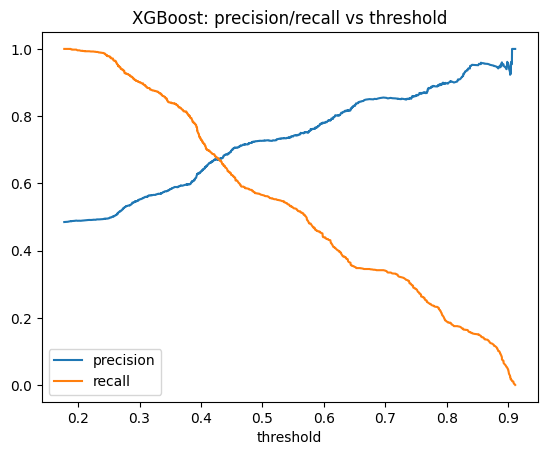

F1-maximizing threshold: 0.357


,model,ROC-AUC,AUC 95% CI,PR-AUC,precision,recall,F1
0,XGBoost @0.5,0.744,"(0.709, 0.776)",0.76,0.704,0.542,0.612
1,XGBoost @0.36,0.744,"(0.709, 0.776)",0.76,0.595,0.844,0.698


,actual_return_rate,count
decile,,
10,0.945946,74
9,0.770270,74
8,0.594595,74
7,0.459459,74
6,0.500000,74
5,0.432432,74
4,0.459459,74
3,0.243243,74
2,0.256757,74


In [ ]:
# pick a threshold using out-of-fold predictions on training set, report test results at both thresholds
final_name = "XGBoost" # chose XGBoost
final_model = best[final_name]

# Out-of-fold probabilities on TRAIN: choose the threshold without touching test
oof = cross_val_predict(final_model, X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)

plt.plot(thr, prec[:-1], label="precision")
plt.plot(thr, rec[:-1], label="recall")
plt.xlabel("threshold"); plt.legend(); plt.title(f"{final_name}: precision/recall vs threshold")
plt.show()

f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
t_best = thr[np.argmax(f1s)]
print("F1-maximizing threshold:", round(t_best, 3))

display(pd.DataFrame([test_report(final_name + " @0.5", final_model, X_test, y_test, 0.5),
                      test_report(final_name + f" @{t_best:.2f}", final_model, X_test, y_test, t_best)]))

# Lift: how well does the top of the ranked list perform?
test_df = pd.DataFrame({"p": final_model.predict_proba(X_test)[:, 1], "y": y_test.values})
test_df["decile"] = pd.qcut(test_df["p"].rank(method="first"), 10, labels=False) + 1
display(test_df.groupby("decile")["y"].agg(["mean", "count"]).sort_index(ascending=False)
        .rename(columns={"mean": "actual_return_rate"}))

^ XGBoost tuning
- Lowering the threshold from 0.5 to 0.36 raised recall from 0.54 to 0.84 and lowers precision from 0.70 to 0.60 (F1 0.61 to 0.70). ROC-AUC is unchanged because the threshold doesn't change the ranking
- Customers ranked by predicted probability: the top decile returned 95% of the time, the top two deciles about 86%, and the bottom three deciles about 23%. The middle deciles (4 to 7) are near 43% to 50%, essentially the overall base rate of 49%
- The model separates likely returners from unlikely ones at the extremes, but cannot distinguish customers in the middle

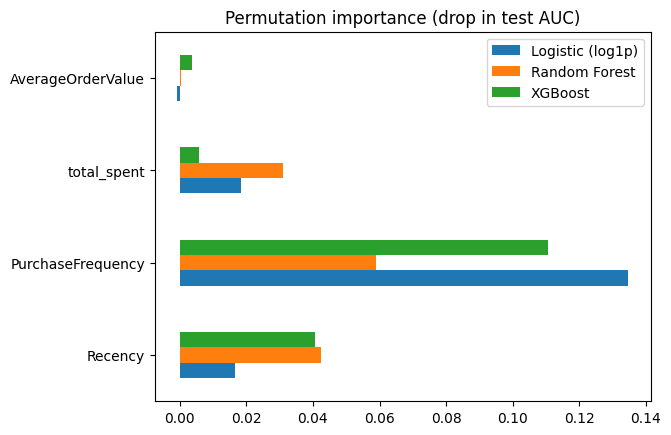

Recency             -0.176647
AverageOrderValue   -0.040802
total_spent          0.233154
PurchaseFrequency    0.775981
dtype: float64


In [ ]:
# looking into which behaviors best predict repeat purchasing
# using permutation importance to shuffle one featuer at a time and measure drop in test AUC
imp = {}
for name in ["Logistic (log1p)", "Random Forest", "XGBoost"]:
    r = permutation_importance(best[name], X_test, y_test, scoring="roc_auc",
                               n_repeats=30, random_state=42)
    imp[name] = pd.Series(r.importances_mean, index=X_test.columns)
pd.DataFrame(imp).plot(kind="barh", title="Permutation importance (drop in test AUC)")
plt.show()

# Direction of effect (logistic only; features are scaled, so coefficients are comparable)
coefs = pd.Series(best["Logistic (log1p)"].named_steps["model"].coef_[0], index=X_train.columns)
print(coefs.sort_values())

PurchaseFrequency (+0.78) dominates as the strongest predictor of repeat purchase, then total_spent (+0.23), Recency (-0.18), and AverageOrderValue (-0.04, near zero). THis is different from our observations through EDA, whereRecency's raw correlation (-0.29) was slightly larger than frequency's (0.26). One likely reason is that recency and frequency overlap (frequent buyers also bough recently), and the model assigns the shared signal mostly to frequency.

In [ ]:
pred = (final_model.predict_proba(X_test)[:, 1] >= t_best).astype(int)
err = X_test.copy()
err["outcome"] = np.select(
    [(y_test == 1) & (pred == 1), (y_test == 1) & (pred == 0),
     (y_test == 0) & (pred == 1), (y_test == 0) & (pred == 0)],
    ["TP (caught)", "FN (missed returner)", "FP (false alarm)", "TN (correct no)"],
    default="other")
print(err["outcome"].value_counts())

outcome
TP (caught)             304
FP (false alarm)        207
TN (correct no)         174
FN (missed returner)     56
Name: count, dtype: int64


In [ ]:
# quick test to understand what each feature contributes to prediction
base_model = best["Logistic (log1p)"]
full = cross_val_score(base_model, X_train, y_train, cv=cv, scoring="roc_auc").mean()
print("all features:", round(full, 3))
for f in X_train.columns:
    cols = [c for c in X_train.columns if c != f]
    s = cross_val_score(base_model, X_train[cols], y_train, cv=cv, scoring="roc_auc").mean()
    print(f"without {f}: {s:.3f} (change {s - full:+.3f})")

all features: 0.734
without Recency: 0.729 (change -0.005)
without PurchaseFrequency: 0.734 (change -0.000)
without total_spent: 0.734 (change +0.000)
without AverageOrderValue: 0.734 (change -0.000)


- At the F1-maximizing threshold the model flags 69% of customers and catches 84% of returners, at a precision of 0.60 (vs. a 49% base rate, about 1.2x lift).
- The dominant error is false alarms: 54% of non-returners are flagged. Missed returners are rare at this threshold, so they are also examined at the default 0.5 threshold.

In [ ]:

baseline_rows = []

# guesses the same thing for everyone, always AUC 0.5
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
baseline_rows.append({"approach": "Dummy (coin flip)",
                      "test ROC-AUC": roc_auc_score(y_test, dummy.predict_proba(X_test)[:, 1])})

# rank customers by one feature (negative recency since fewer days = more likely to return)
baseline_rows.append({"approach": "Rule: Recency only",
                      "test ROC-AUC": roc_auc_score(y_test, -X_test["Recency"])})
baseline_rows.append({"approach": "Rule: PurchaseFrequency only",
                      "test ROC-AUC": roc_auc_score(y_test, X_test["PurchaseFrequency"])})

# simple RFM score: add up recency and frequency ranks
rfm_score = (-X_test["Recency"]).rank(pct=True) + X_test["PurchaseFrequency"].rank(pct=True)
baseline_rows.append({"approach": "Rule: RFM score",
                      "test ROC-AUC": roc_auc_score(y_test, rfm_score)})

# tuned models from the grid search
for name, model in best.items():
    baseline_rows.append({"approach": name,
                          "test ROC-AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])})

baseline_table = pd.DataFrame(baseline_rows).sort_values("test ROC-AUC", ascending=False)
display(baseline_table.round(3).reset_index(drop=True))


,approach,test ROC-AUC
0,XGBoost,0.744
1,Random Forest,0.742
2,Logistic (log1p),0.736
3,KNN,0.735
4,Logistic (scaled),0.735
5,Rule: RFM score,0.732
6,Decision Tree,0.725
7,Rule: PurchaseFrequency only,0.713
8,Rule: Recency only,0.683
9,Dummy (coin flip),0.500


This helps demonstrates which methods are actually worth it. Here I compared them to a dummy classifier where the AUC is always 0.5 and added in rules to see which had the most impact. The gap between the best rule and the best model shows how much the ML models add on top of just sorting customers.

In [ ]:
# paired bootstrap, is XGBoost actually better or just lucky on this test set?
def paired_auc_difference(model_a, model_b, X, y, n_boot=2000, seed=42):
    proba_a = model_a.predict_proba(X)[:, 1]
    proba_b = model_b.predict_proba(X)[:, 1]
    y_arr = np.asarray(y)
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_arr), len(y_arr))   # resample test customers
        if len(np.unique(y_arr[idx])) < 2:              # need both classes to get AUC
            continue
        # score both models on the same resample
        diffs.append(roc_auc_score(y_arr[idx], proba_a[idx]) -
                     roc_auc_score(y_arr[idx], proba_b[idx]))
    observed = roc_auc_score(y_arr, proba_a) - roc_auc_score(y_arr, proba_b)
    low, high = np.percentile(diffs, [2.5, 97.5])
    return observed, low, high

reference = "XGBoost"
rows = []
for name, model in best.items():
    if name == reference:
        continue
    diff, low, high = paired_auc_difference(best[reference], model, X_test, y_test)
    rows.append({"comparison": f"{reference} vs {name}",
                 "AUC difference": round(diff, 3),
                 "95% CI": f"({low:+.3f}, {high:+.3f})",
                 "real difference?": "yes" if low > 0 or high < 0 else "no"})  # no = CI includes 0
display(pd.DataFrame(rows))

,comparison,AUC difference,95% CI,real difference?
0,XGBoost vs Logistic (scaled),0.009,"(-0.003, +0.021)",no
1,XGBoost vs Logistic (log1p),0.008,"(-0.004, +0.020)",no
2,XGBoost vs KNN,0.009,"(-0.005, +0.023)",no
3,XGBoost vs Decision Tree,0.019,"(+0.006, +0.032)",yes
4,XGBoost vs Random Forest,0.002,"(-0.005, +0.008)",no


Here I resampled the test customers 2,000 times, scored XGBoost and each other model on the same customers each time, and took the difference in AUC. If the 95% range of that difference includes 0, we can’t say XGBoost is actually better.


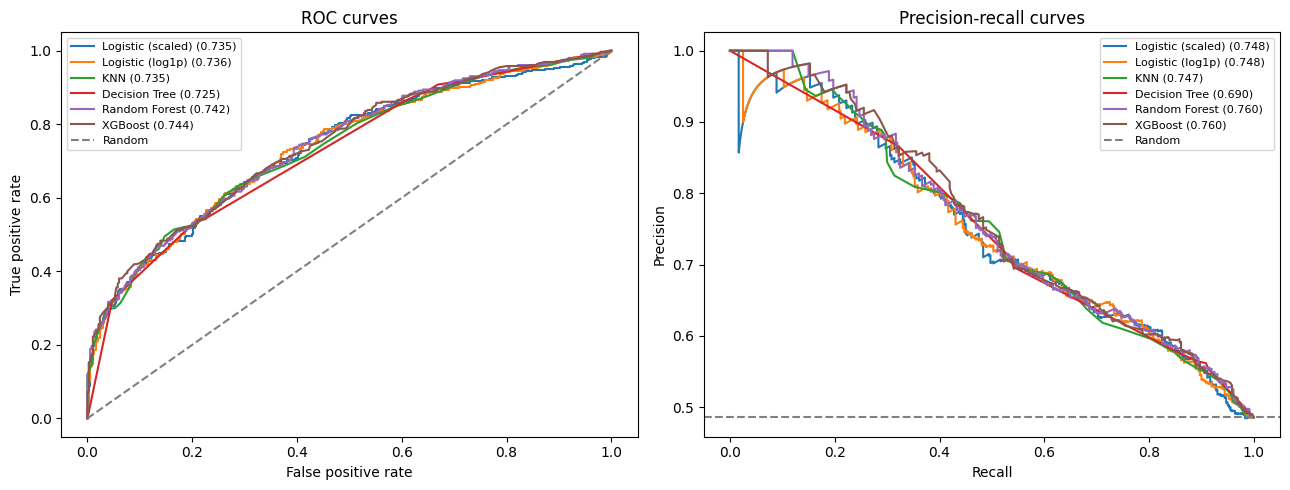

In [ ]:
# ROC and precision-recall curves for all models on one chart
from sklearn.metrics import roc_curve

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5))

for name, model in best.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax_roc.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, proba):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ax_pr.plot(rec, prec, label=f"{name} ({average_precision_score(y_test, proba):.3f})")

# what random guessing looks like
ax_roc.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
ax_pr.axhline(y_test.mean(), linestyle="--", color="gray", label="Random")

ax_roc.set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate")
ax_pr.set(title="Precision-recall curves", xlabel="Recall", ylabel="Precision")
ax_roc.legend(fontsize=8)
ax_pr.legend(fontsize=8)
plt.tight_layout()
plt.show()

Plotted every model’s ROC and precision-recall curves together to see if any model does better at certain thresholds. If the curves mostly overlap, the models are basically interchangeable, which matches the bootstrap results.

In [ ]:
# if marketing only contacts the top 10/20/30% of customers, how many returners does each model catch?
top_shares = [0.10, 0.20, 0.30]
base_rate = y_test.mean()
total_returners = y_test.sum()
capture_rows = []

def add_capture_row(name, scores):
    order = np.argsort(-np.asarray(scores))     # highest score first
    y_sorted = np.asarray(y_test)[order]
    row = {"model": name}
    for share in top_shares:
        n = int(round(share * len(y_sorted)))
        found = y_sorted[:n].sum()
        pct = int(share * 100)
        row[f"top {pct}% capture"] = round(found / total_returners, 3)   # % of all returners found
        row[f"top {pct}% lift"] = round((found / n) / base_rate, 2)      # vs random (1.0 = random)
    capture_rows.append(row)

for name, model in best.items():
    add_capture_row(name, model.predict_proba(X_test)[:, 1])
add_capture_row("Rule: RFM score", rfm_score)   # compare against the simple rule too

display(pd.DataFrame(capture_rows).sort_values("top 20% capture", ascending=False).reset_index(drop=True))
print("Return rate in test set:", round(base_rate, 3))

,model,top 10% capture,top 10% lift,top 20% capture,top 20% lift,top 30% capture,top 30% lift
0,XGBoost,0.194,1.95,0.353,1.77,0.475,1.59
1,Logistic (scaled),0.194,1.95,0.347,1.74,0.458,1.53
2,Logistic (log1p),0.189,1.89,0.344,1.72,0.458,1.53
3,Decision Tree,0.175,1.75,0.344,1.72,0.444,1.48
4,Random Forest,0.197,1.97,0.342,1.71,0.469,1.57
5,KNN,0.194,1.95,0.331,1.66,0.472,1.58
6,Rule: RFM score,0.178,1.78,0.331,1.66,0.458,1.53


Return rate in test set: 0.486


Since a retention campaign would only reach the customers ranked highest, we checked how many actual returners each model finds in its top 10%, 20%, and 30%. Lift compares that to random targeting: a lift of 1.8 means those customers are 1.8 times more likely to return than average.

Reflections:
A simple RFM score (just adding up recency and frequency ranks, no training) got 0.732 AUC, while the best model (XGBoost) got 0.744. The ML models only add about 0.01 on top of a basic sort, and ranking by purchase frequency alone already gets 0.713.
In the paired bootstrap, XGBoost was not significantly better than logistic regression, KNN, or random forest (all their CIs include 0). It only beat the single decision tree (+0.019).
The ROC and precision-recall curves mostly overlap, which matches the bootstrap.
If marketing contacts the top 20% of customers, every model finds about 33–35% of returners, a lift of about 1.7x over random. The RFM rule gets 1.66x, so it’s close behind.

Since the models are basically tied, we’d go with logistic regression because it performs the same as XGBoost and is the easiest to explain. The limiting factor is the four features, not the model, so the next step would be adding features like customer tenure, days between orders, or country.

In [ ]:
# new customer features built from the "past" transactions (before the cutoff, so no leakage)
g = past.groupby("CustomerID")
new_feats = pd.DataFrame({
    "FirstPurchaseDate": g["InvoiceDate"].min(),
    "LastPurchaseDate2": g["InvoiceDate"].max(),
    "UniqueProducts": g["StockCode"].nunique(),        # how many different products they bought
    "IsUK": (g["Country"].first() == "United Kingdom").astype(int),
})

# orders placed in the 90 days right before the cutoff
recent = past[past["InvoiceDate"] > cutoff_date - pd.Timedelta(days=90)]
new_feats["OrdersLast90Days"] = recent.groupby("CustomerID")["InvoiceNo"].nunique()
new_feats["OrdersLast90Days"] = new_feats["OrdersLast90Days"].fillna(0)

# tenure = how long they've been a customer
new_feats["Tenure"] = (cutoff_date - new_feats["FirstPurchaseDate"]).dt.days

# average days between orders (one-time buyers don't have a gap, so we give them their tenure)
n_orders = g["InvoiceNo"].nunique()
active_days = (new_feats["LastPurchaseDate2"] - new_feats["FirstPurchaseDate"]).dt.days
new_feats["AvgDaysBetweenOrders"] = np.where(n_orders > 1, active_days / (n_orders - 1),
                                             new_feats["Tenure"])

new_feats = new_feats.drop(columns=["FirstPurchaseDate", "LastPurchaseDate2"]).reset_index()

# attach to df, keeping the same row index so the train/test split still lines up
df2 = df[["CustomerID"]].merge(new_feats, on="CustomerID", how="left")
df2.index = df.index
extra = ["Tenure", "AvgDaysBetweenOrders", "UniqueProducts", "OrdersLast90Days", "IsUK"]
for col in extra:
    df[col] = df2[col]

display(df[extra].describe().round(1))

,Tenure,AvgDaysBetweenOrders,UniqueProducts,OrdersLast90Days,IsUK
count,3701.0,3701.0,3701.0,3701.0,3701.0
mean,191.7,95.5,53.0,1.2,0.9
std,95.4,83.0,73.2,2.2,0.3
min,0.0,0.0,1.0,0.0,0.0
25%,121.0,31.9,14.0,0.0,1.0
50%,210.0,65.0,31.0,1.0,1.0
75%,273.0,142.0,66.0,1.0,1.0
max,310.0,310.0,1481.0,55.0,1.0


In [ ]:


# own CV splitter so this doesn't depend on the "cv" variable from earlier cells
cv_feat = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

# compare: original 4 features vs adding the new ones vs a smaller set (recency + frequency only)
feature_sets = {
    "original 4": features,
    "original + new": features + extra,
    "recency + frequency only": ["Recency", "PurchaseFrequency"],
}

results = []
for set_name, cols in feature_sets.items():
    Xtr = df.loc[X_train.index, cols].fillna(0)   # same customers as before
    Xte = df.loc[X_test.index, cols].fillna(0)
    for model_name in ["Logistic (log1p)", "XGBoost"]:
        model = clone(best[model_name])           # fresh copy with the tuned settings
        cv_auc = cross_val_score(model, Xtr, y_train, cv=cv_feat, scoring="roc_auc").mean()
        model.fit(Xtr, y_train)
        test_auc = roc_auc_score(y_test, model.predict_proba(Xte)[:, 1])
        results.append({"features": set_name, "model": model_name,
                        "CV AUC": round(cv_auc, 3), "test AUC": round(test_auc, 3)})

display(pd.DataFrame(results))

,features,model,CV AUC,test AUC
0,original 4,Logistic (log1p),0.734,0.736
1,original 4,XGBoost,0.744,0.744
2,original + new,Logistic (log1p),0.751,0.751
3,original + new,XGBoost,0.751,0.754
4,recency + frequency only,Logistic (log1p),0.736,0.732
5,recency + frequency only,XGBoost,0.739,0.743


Adding the new features (tenure, average days between orders, number of unique products, orders in the last 90 days, and country) improved both models: logistic regression went from 0.736 to 0.751 test AUC and XGBoost from 0.744 to 0.754. The improvement shows up in both cross-validation and the test set, so it’s consistent and not luck. With the new features, logistic regression performs the same as XGBoost (0.751 CV AUC for both).

Using only recency and frequency scored about the same as the original 4 features (0.736 vs 0.734 CV AUC for logistic regression), so total spent and average order value don’t add anything and can be removed.

This supports our main conclusion: changing the model barely mattered, but adding more customer information did. The best setup is logistic regression with recency, frequency, and the new features, since it matches XGBoost and is easier to explain.